# Progetto 2 – Test di robustezza del modello del prestito

**Come usare questo notebook**
- Esegui le celle **una alla volta, dall'alto verso il basso** (`Shift + Invio`).
- Non devi modificare il codice: leggi i commenti (le righe con `#`) e i risultati.
- Dopo ogni passo trovi un riquadro **Annota**: scrivi le tue osservazioni nel file di appunti.

**Prima di iniziare:** compila la tabella dei criteri di accettazione nel report (sezione 4). I criteri si fissano **prima** di vedere i risultati, come nel Progetto 1.

**La domanda del progetto:** il modello resta affidabile quando i dati sono imperfetti, quando cambia un dettaglio irrilevante e quando riceve casi estremi?

## Passo 0 – Preparazione
Installa gli strumenti. Ci vuole circa un minuto.

In [1]:
!pip install -q fairlearn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score
from fairlearn.datasets import fetch_adult
print("Tutto pronto!")

Tutto pronto!


## Passo 1 – Ricostruire il modello del Progetto 1
Stessi dati, stessa divisione 70/30, stesso modello, sesso ed etnia esclusi. Così i risultati partono **esattamente** da dove eri arrivato.

**Controlla:** accuratezza e recall devono essere uguali a quelli del Progetto 1 (85,5% e 59,8%). Se sono diversi, qualcosa non torna: fermati e verifica. È il tuo primo test di regressione.

In [2]:
dati = fetch_adult(as_frame=True)
X = dati.data
y = (dati.target == ">50K").astype(int)

X_modello = X.drop(columns=["sex", "race"])   # come nel Progetto 1

def crea_modello():
    # La stessa ricetta del Progetto 1
    return make_pipeline(
        make_column_transformer(
            (StandardScaler(), make_column_selector(dtype_include="number")),
            (OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_exclude="number")),
        ),
        LogisticRegression(max_iter=1000),
    )

X_train, X_test, y_train, y_test = train_test_split(
    X_modello, y, test_size=0.3, random_state=42, stratify=y)
modello = crea_modello().fit(X_train, y_train)

def misura(X_dati):
    # Accuratezza e recall del modello su una versione dei dati di test
    previsioni = modello.predict(X_dati)
    return accuracy_score(y_test, previsioni), recall_score(y_test, previsioni)

acc_base, rec_base = misura(X_test)
print(f"Accuratezza: {acc_base:.1%}")
print(f"Recall:      {rec_base:.1%}")

Accuratezza: 85.5%
Recall:      59.8%


## Passo 2 – La variabilità naturale
Prima di disturbare i dati, misuriamo quanto cambia il recall **da solo**, cambiando soltanto la divisione casuale tra addestramento e test. Questo è il "rumore di fondo" del modello.

**Perché serve:** se il recall oscilla già di 1-2 punti senza toccare nulla, un calo di 1 punto sotto disturbo non dimostra niente. È il riferimento per leggere tutti i passi successivi.

In [4]:
risultati = []
for seme in range(5):
    Xa, Xb, ya, yb = train_test_split(X_modello, y, test_size=0.3, random_state=seme, stratify=y)
    m = crea_modello().fit(Xa, ya)
    risultati.append(recall_score(yb, m.predict(Xb)))

risultati = np.array(risultati) * 100
print("Recall con 5 divisioni diverse:", np.round(risultati, 1))
print(f"Media: {risultati.mean():.1f}   Minimo: {risultati.min():.1f}   Massimo: {risultati.max():.1f}")
print(f"Variabilità naturale: circa ±{(risultati.max() - risultati.min()) / 2:.1f} punti")

Recall con 5 divisioni diverse: [59.8 62.3 59.3 59.7 59.1]
Media: 60.0   Minimo: 59.1   Massimo: 62.3
Variabilità naturale: circa ±1.6 punti


**Annota:** quanto vale la variabilità naturale? Scrivila nel report: ogni calo più piccolo di questo valore va considerato "non significativo".

## Passo 3 – La curva di degrado
Aggiungiamo disturbi sempre più forti ai dati di test e misuriamo il recall a ogni livello. Due tipi di disturbo:

1. **Rumore** su età e ore lavorate: ogni valore viene spostato a caso di qualche percento (1%, 5%, 10%, 20%), come un errore di inserimento o di misura.
2. **Valori mancanti** nella professione: una quota di persone (10%, 20%, 50%) perde l'informazione, come un campo non compilato.

Ogni livello viene ripetuto 5 volte con disturbi diversi, e si guarda la media.

Rumore su età e ore lavorate
  ±  0%  recall  59.8%   variazione  +0.0 punti
  ±  1%  recall  59.8%   variazione  +0.0 punti
  ±  5%  recall  59.9%   variazione  +0.1 punti
  ± 10%  recall  59.9%   variazione  +0.0 punti
  ± 20%  recall  59.6%   variazione  -0.3 punti

Professione mancante
    0%  recall  59.8%   variazione  +0.0 punti
   10%  recall  57.5%   variazione  -2.4 punti
   20%  recall  55.2%   variazione  -4.7 punti
   50%  recall  48.0%   variazione -11.8 punti


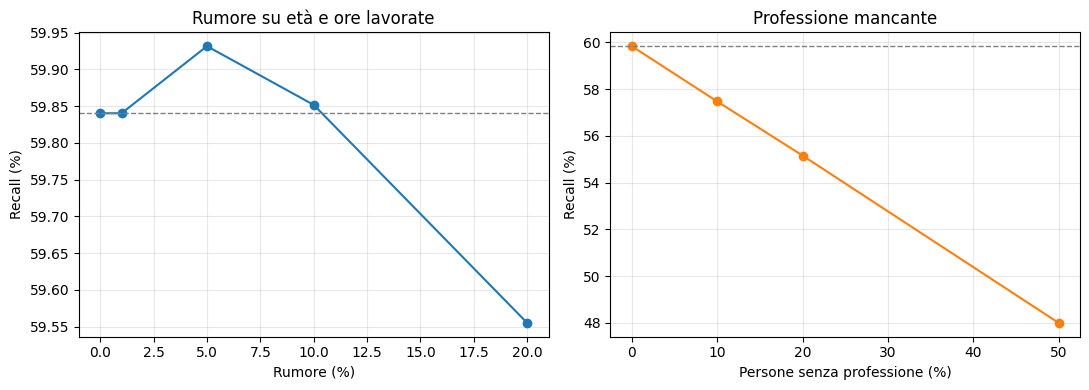

In [5]:
def aggiungi_rumore(X_dati, colonne, livello, seme):
    # Sposta ogni valore di una percentuale casuale (livello 0.05 = circa ±5%)
    rng = np.random.default_rng(seme)
    X_nuovo = X_dati.copy()
    for col in colonne:
        X_nuovo[col] = (X_nuovo[col] * (1 + rng.normal(0, livello, len(X_nuovo)))).clip(lower=0)
    return X_nuovo

def togli_valori(X_dati, colonna, quota, seme):
    # Cancella il valore di una colonna per una quota casuale di persone
    rng = np.random.default_rng(seme)
    X_nuovo = X_dati.copy()
    da_togliere = rng.random(len(X_nuovo)) < quota
    X_nuovo.loc[da_togliere, colonna] = np.nan
    return X_nuovo

livelli_rumore = [0, 0.01, 0.05, 0.10, 0.20]
recall_rumore = [np.mean([misura(aggiungi_rumore(X_test, ["age", "hours-per-week"], l, s))[1] for s in range(5)]) * 100
                 for l in livelli_rumore]

livelli_mancanti = [0, 0.10, 0.20, 0.50]
recall_mancanti = [np.mean([misura(togli_valori(X_test, "occupation", q, s))[1] for s in range(5)]) * 100
                   for q in livelli_mancanti]

print("Rumore su età e ore lavorate")
for l, r in zip(livelli_rumore, recall_rumore):
    print(f"  ±{l:>4.0%}  recall {r:5.1f}%   variazione {r - rec_base*100:+5.1f} punti")
print("\nProfessione mancante")
for q, r in zip(livelli_mancanti, recall_mancanti):
    print(f"  {q:>4.0%}  recall {r:5.1f}%   variazione {r - rec_base*100:+5.1f} punti")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([l * 100 for l in livelli_rumore], recall_rumore, marker="o")
ax[0].set(title="Rumore su età e ore lavorate", xlabel="Rumore (%)", ylabel="Recall (%)")
ax[1].plot([q * 100 for q in livelli_mancanti], recall_mancanti, marker="o", color="tab:orange")
ax[1].set(title="Professione mancante", xlabel="Persone senza professione (%)", ylabel="Recall (%)")
for a in ax:
    a.axhline(rec_base * 100, color="grey", linestyle="--", linewidth=1)
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Annota:** la colonna "variazione" è negativa quando il recall scende. A quale livello il calo supera la variabilità naturale del Passo 2? Il modello scende piano o crolla? Confronta con i tuoi criteri: il livello "realistico" che hai scelto rispetta la soglia?

## Passo 4 – I test metamorfici
Qui non serve conoscere la risposta giusta: verifichiamo **come deve cambiare** la risposta quando modifichiamo l'input.

- **4a Indifferenza:** 1 ora in più a settimana non deve cambiare la decisione.
- **4b Monotonia:** 5.000 dollari in più di reddito da capitale non devono **abbassare** la probabilità di reddito alto.
- **4c Controfattuale:** la stessa persona con relationship cambiata da Husband a Wife (e viceversa) deve ricevere la stessa decisione. È la verifica dell'ipotesi del Progetto 1.

In [7]:
decisioni_base = modello.predict(X_test)
prob_base = modello.predict_proba(X_test)[:, 1]
n = len(X_test)

# 4a Indifferenza: una ora in più
X_4a = X_test.copy()
X_4a["hours-per-week"] = X_4a["hours-per-week"] + 1
cambiate = (modello.predict(X_4a) != decisioni_base).sum()
print(f"4a Indifferenza: decisioni cambiate con +1 ora: {cambiate} su {n} ({cambiate / n:.2%})")

# 4b Monotonia: più reddito da capitale
X_4b = X_test.copy()
X_4b["capital-gain"] = X_4b["capital-gain"] + 5000
violazioni = (modello.predict_proba(X_4b)[:, 1] < prob_base - 1e-9).sum()
print(f"4b Monotonia: casi in cui la probabilità scende con +5.000 dollari: {violazioni} su {n}")

4a Indifferenza: decisioni cambiate con +1 ora: 55 su 14653 (0.38%)
4b Monotonia: casi in cui la probabilità scende con +5.000 dollari: 0 su 14653


In [8]:
# 4c Controfattuale: scambiamo Husband e Wife, lasciando tutto il resto uguale
mariti = (X_test["relationship"] == "Husband")
mogli = (X_test["relationship"] == "Wife")

X_4c = X_test.copy()
X_4c.loc[mariti, "relationship"] = "Wife"
X_4c.loc[mogli, "relationship"] = "Husband"
decisioni_4c = modello.predict(X_4c)
prob_4c = modello.predict_proba(X_4c)[:, 1]

for nome, gruppo, nuovo in [("Husband → Wife", mariti, "Wife"), ("Wife → Husband", mogli, "Husband")]:
    tot = gruppo.sum()
    da_si_a_no = ((decisioni_base == 1) & (decisioni_4c == 0) & gruppo).sum()
    da_no_a_si = ((decisioni_base == 0) & (decisioni_4c == 1) & gruppo).sum()
    variazione = (prob_4c[gruppo] - prob_base[gruppo]).mean() * 100
    print(f"{nome}: {tot} persone")
    print(f"   da 'sì' a 'no': {da_si_a_no}   da 'no' a 'sì': {da_no_a_si}   "
          f"decisioni cambiate: {(da_si_a_no + da_no_a_si) / tot:.1%}")
    print(f"   variazione media della probabilità: {variazione:+.1f} punti")

Husband → Wife: 5911 persone
   da 'sì' a 'no': 0   da 'no' a 'sì': 666   decisioni cambiate: 11.3%
   variazione media della probabilità: +8.1 punti
Wife → Husband: 712 persone
   da 'sì' a 'no': 90   da 'no' a 'sì': 0   decisioni cambiate: 12.6%
   variazione media della probabilità: -7.8 punti


**Annota:** quale relazione è rispettata e quale no? Nel controfattuale, in che direzione cambiano le decisioni? Cosa dimostra questo sull'ipotesi del Progetto 1?

*Nota sulla monotonia:* la regressione logistica è un modello lineare, quindi per costruzione non può "tornare indietro" su una singola colonna. Un risultato di 0 violazioni è atteso. È comunque un test utile: con modelli più complessi (alberi, reti neurali) le violazioni capitano davvero.

## Passo 5 – I casi limite
Costruiamo una persona "tipica" (i valori più comuni del dataset) e poi la modifichiamo un dettaglio alla volta con valori estremi, rari o incoerenti. Guardiamo la probabilità di reddito alto e la decisione.

**Cosa cercare:** risposte strane, salti improvvisi, casi assurdi accettati senza esitazione.

In [9]:
# Persona tipica: valore mediano per i numeri, valore più comune per le categorie
base = {}
for col in X_modello.columns:
    if pd.api.types.is_numeric_dtype(X_modello[col]):
        base[col] = X_modello[col].median()
    else:
        base[col] = X_modello[col].mode()[0]

casi = [
    ("Persona tipica", {}),
    ("Età 17", {"age": 17}),
    ("Età 90", {"age": 90}),
    ("1 ora a settimana", {"hours-per-week": 1}),
    ("99 ore a settimana", {"hours-per-week": 99}),
    ("Reddito da capitale 99.999", {"capital-gain": 99999}),
    ("Professione mancante", {"occupation": np.nan}),
    ("Dottorato", {"education": "Doctorate", "education-num": 16}),
    ("Incoerente: 17 anni e dottorato", {"age": 17, "education": "Doctorate", "education-num": 16}),
]

righe = []
for descrizione, modifiche in casi:
    persona = pd.DataFrame([{**base, **modifiche}])
    for col in X_modello.columns:
        persona[col] = persona[col].astype(X_modello[col].dtype)
    p = modello.predict_proba(persona)[0, 1]
    righe.append({"Caso": descrizione, "Probabilità reddito alto": f"{p:.0%}", "Decisione": "sì" if p >= 0.5 else "no"})

pd.DataFrame(righe)

,Caso,Probabilità reddito alto,Decisione
0,Persona tipica,37%,no
1,Età 17,27%,no
2,Età 90,69%,sì
3,1 ora a settimana,16%,no
4,99 ore a settimana,77%,sì
5,Reddito da capitale 99.999,100%,sì
6,Professione mancante,19%,no
7,Dottorato,78%,sì
8,Incoerente: 17 anni e dottorato,68%,sì


**Annota:** quali risposte ti sembrano sensate e quali no? Il caso incoerente (17 anni con dottorato) viene accettato senza segnali? Cosa dovrebbe fare un sistema reale con un input così?

## Passo 6 – Le tue conclusioni
Rispondi per iscritto, nel report:

1. Quanto vale la variabilità naturale del modello, e perché è importante?
2. Il modello è robusto al rumore e ai valori mancanti? A quale livello inizia a cedere?
3. Quali relazioni metamorfiche sono rispettate e quali no?
4. L'ipotesi del Progetto 1 su relationship è confermata? Con quali numeri?
5. Quali casi limite danno risposte poco sensate?
6. Approveresti il rilascio dal punto di vista della robustezza? A quali condizioni?

Usa la struttura di report nella guida al Progetto 2.